<a href="https://colab.research.google.com/github/Mayada-bio/Bulk-RNASeq-Differential-Expression-Pipeline/blob/main/Layer2A_Bulk_RNASeq_Differential_Expression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)

Installing package(s) 'BiocVersion', 'DESeq2', 'airway', 'EnhancedVolcano',
  'apeglm'

also installing the dependencies ‘XVector’, ‘formatR’, ‘abind’, ‘SparseArray’, ‘lambda.r’, ‘futile.options’, ‘numDeriv’, ‘bdsmatrix’, ‘mvtnorm’, ‘Seqinfo’, ‘S4Arrays’, ‘DelayedArray’, ‘futile.logger’, ‘snow’, ‘BH’, ‘plyr’, ‘coda’, ‘bbmle’, ‘S4Vectors’, ‘IRanges’, ‘GenomicRanges’, ‘SummarizedExperiment’, ‘BiocGenerics’, ‘Biobase’, ‘BiocParallel’, ‘matrixStats’, ‘locfit’, ‘MatrixGenerics’, ‘RcppArmadillo’, ‘ggrepel’, ‘emdbook’, ‘RcppEigen’, ‘RcppNumerical’


Loading required package: S4Vectors

Loading required package: stats4

Loading required package: BiocGen

✅ Bioinformatic Suite & Libraries Successfully Loaded!

📊 Raw Matrix Dimensions (Genes x Samples): 63677 8 
🧹 Filtered Matrix Dimensions (Pre-processed): 22369 8 


estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



ℹ️ Target Coefficient for Shrinkage: dex_untrt_vs_trt 


using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895

using ntop=500 top features by variance



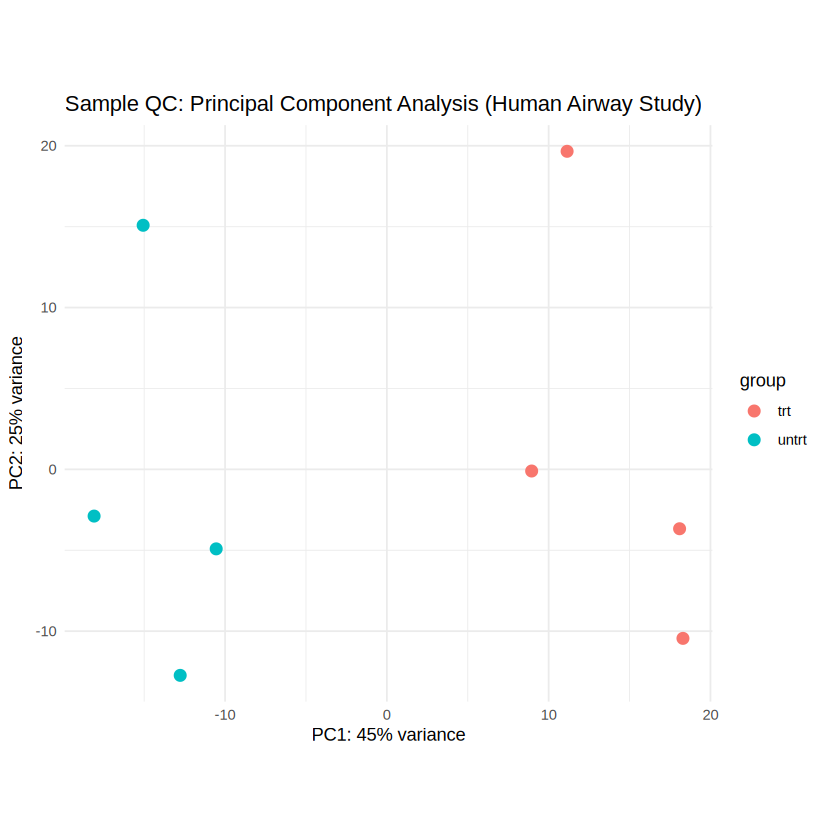


================ 🔬 STATISTICAL DEG SUMMARY ================
Total Human Genes Evaluated: 22369 
Statistically Significant DEGs (padj < 0.05 & |log2FC| > 1): 696 
  - Up-regulated Genes: 311 
  - Down-regulated Genes: 385 



Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the EnhancedVolcano package.
  Please report the issue to the authors.”
Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the EnhancedVolcano package.
  Please report the issue to the authors.”


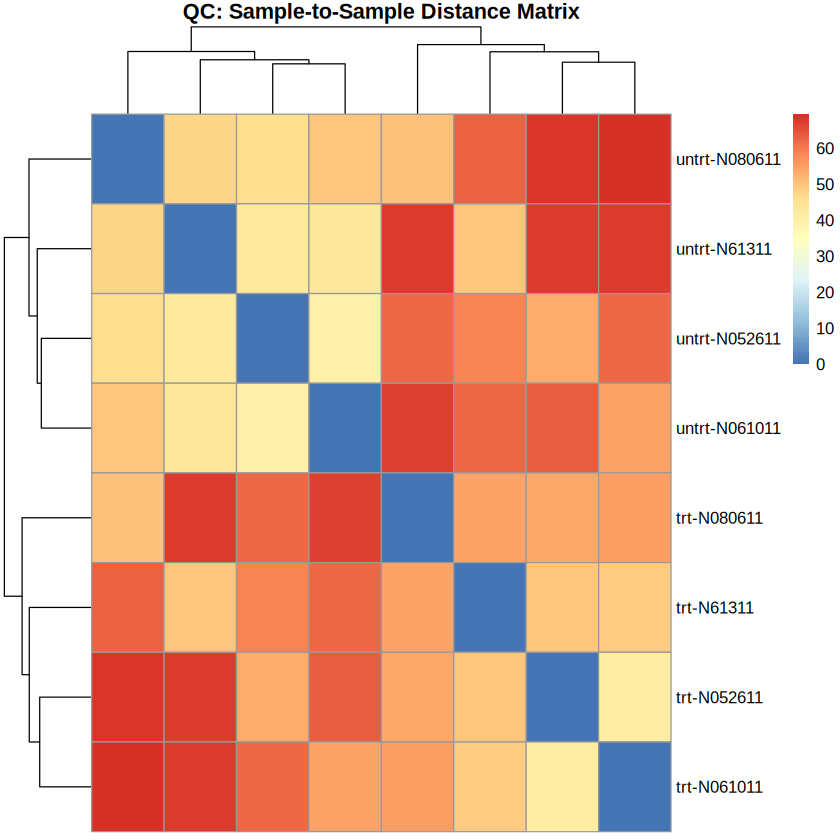

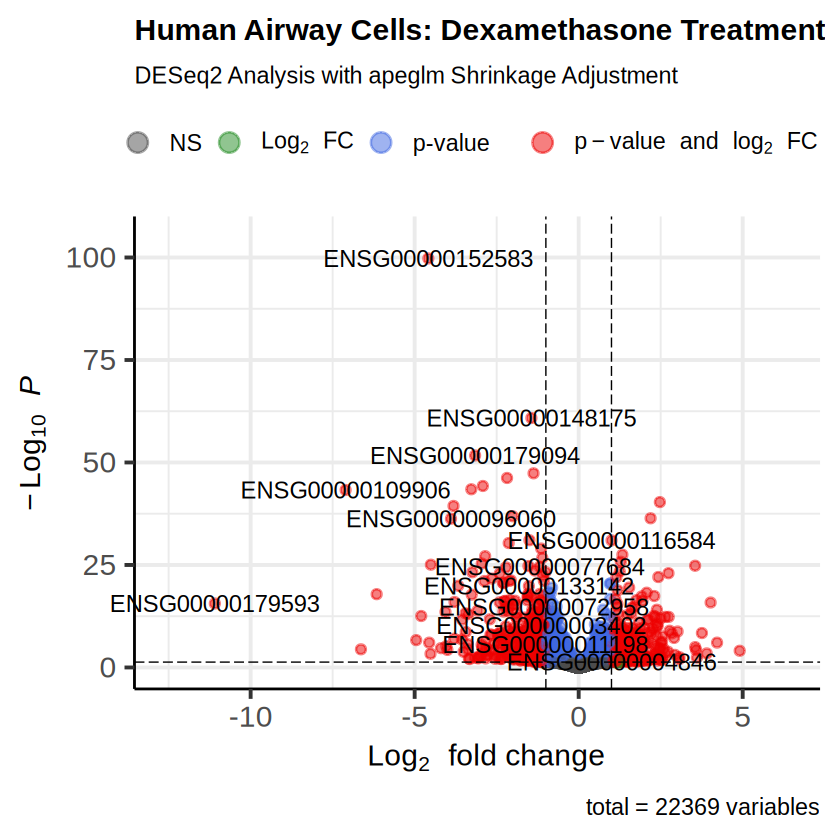

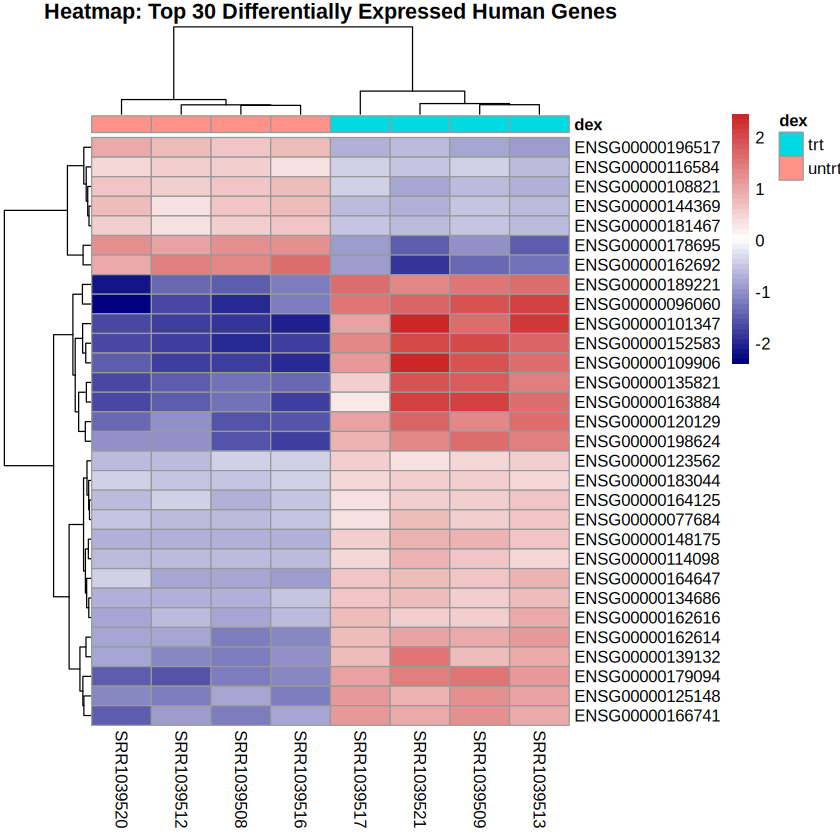

In [ ]:
# ==============================================================================
# Layer 2A: Academic Bulk RNA-Seq Pipeline (Real Human Airway Dataset)
# Author: Mayada Mohammed Elfadil (M.Sc. in Bioinformatics)
# Benchmark Dataset: Human Airway Smooth Muscle Cells
# ==============================================================================

# Step 1: Install & Load Core Bioconductor & CRAN Packages
if (!requireNamespace("BiocManager", quietly = TRUE)) install.packages("BiocManager")

BiocManager::install(c("DESeq2", "airway", "EnhancedVolcano", "apeglm"), update = FALSE, ask = FALSE)
install.packages(c("ggplot2", "pheatmap", "dplyr"), quiet = TRUE)

library(DESeq2)
library(airway)
library(EnhancedVolcano)
library(apeglm)
library(ggplot2)
library(pheatmap)
library(dplyr)

cat("✅ Bioinformatic Suite & Libraries Successfully Loaded!\n\n")

# ------------------------------------------------------------------------------
# Step 2: Load Real Biological Benchmark Dataset (airway)
# ------------------------------------------------------------------------------
data("airway")
dds_raw <- airway

cat("📊 Raw Matrix Dimensions (Genes x Samples):", dim(dds_raw), "\n")

# Extract Raw Count Matrix & Phenotypic Metadata
countData <- assay(dds_raw)
colData <- as.data.frame(colData(dds_raw))

# ------------------------------------------------------------------------------
# Step 3: Low-Count Gene Filtering & DESeq2 Setup
# ------------------------------------------------------------------------------
# Clean out unexpressed/lowly expressed genes (at least 10 total reads)
keep <- rowSums(countData) >= 10
countData_clean <- countData[keep, ]
cat("🧹 Filtered Matrix Dimensions (Pre-processed):", dim(countData_clean), "\n")

# Construct DESeq2 Object
dds <- DESeqDataSetFromMatrix(countData = countData_clean,
                              colData = colData,
                              design = ~ dex)

# Run DESeq2 Differential Expression Analysis
dds <- DESeq(dds)

# Dynamically extract coefficient name to avoid lfcShrink naming mismatch
coef_name <- resultsNames(dds)[2]
cat("ℹ️ Target Coefficient for Shrinkage:", coef_name, "\n")

# Apply Log2 Fold Change Shrinkage (apeglm)
res <- lfcShrink(dds, coef = coef_name, type = "apeglm")
vsd <- vst(dds, blind = FALSE)

# ------------------------------------------------------------------------------
# Step 4: Publication-Grade Quality Control (PCA & Sample Correlation)
# ------------------------------------------------------------------------------
# A. Principal Component Analysis (PCA)
print(plotPCA(vsd, intgroup = "dex") +
      ggtitle("Sample QC: Principal Component Analysis (Human Airway Study)") +
      theme_minimal())

# B. Sample Distance Heatmap
sampleDists <- dist(t(assay(vsd)))
sampleDistMatrix <- as.matrix(sampleDists)
rownames(sampleDistMatrix) <- paste(vsd$dex, vsd$cell, sep="-")
colnames(sampleDistMatrix) <- NULL

pheatmap(sampleDistMatrix,
         clustering_distance_rows = sampleDists,
         clustering_distance_cols = sampleDists,
         main = "QC: Sample-to-Sample Distance Matrix")

# ------------------------------------------------------------------------------
# Step 5: Statistical Summary & File Export
# ------------------------------------------------------------------------------
sig_genes <- subset(res, padj < 0.05 & abs(log2FoldChange) > 1)

cat("\n================ 🔬 STATISTICAL DEG SUMMARY ================\n")
cat("Total Human Genes Evaluated:", nrow(res), "\n")
cat("Statistically Significant DEGs (padj < 0.05 & |log2FC| > 1):", nrow(sig_genes), "\n")
cat("  - Up-regulated Genes:", sum(sig_genes$log2FoldChange > 1, na.rm=TRUE), "\n")
cat("  - Down-regulated Genes:", sum(sig_genes$log2FoldChange < -1, na.rm=TRUE), "\n")
cat("============================================================\n\n")

# Export DEGs Table to CSV
write.csv(as.data.frame(sig_genes), "human_airway_significant_DEGs.csv")

# ------------------------------------------------------------------------------
# Step 6: Advanced Publication Visualizations
# ------------------------------------------------------------------------------
# A. Enhanced Volcano Plot
EnhancedVolcano(res,
    lab = rownames(res),
    x = 'log2FoldChange',
    y = 'padj',
    title = 'Human Airway Cells: Dexamethasone Treatment',
    subtitle = 'DESeq2 Analysis with apeglm Shrinkage Adjustment',
    pCutoff = 0.05,
    FCcutoff = 1.0)

# B. Expression Heatmap of Top 30 DEGs
top30_genes <- head(rownames(sig_genes[order(sig_genes$padj), ]), 30)
mat <- assay(vsd)[top30_genes, ]
mat <- mat - rowMeans(mat)

pheatmap(mat,
         annotation_col = colData["dex"],
         main = "Heatmap: Top 30 Differentially Expressed Human Genes",
         color = colorRampPalette(c("navy", "white", "firebrick3"))(50))

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)

Installing package(s) 'clusterProfiler', 'org.Hs.eg.db'

also installing the dependencies ‘fontBitstreamVera’, ‘fontLiberation’, ‘fontquiver’, ‘gridGraphics’, ‘gdtools’, ‘lazyeval’, ‘tweenr’, ‘polyclip’, ‘png’, ‘Biostrings’, ‘ggplotify’, ‘patchwork’, ‘ape’, ‘ggiraph’, ‘tidytree’, ‘treeio’, ‘ggforce’, ‘RSQLite’, ‘KEGGREST’, ‘aplot’, ‘DOSE’, ‘ggfun’, ‘ggnewscale’, ‘ggtangle’, ‘ggtree’, ‘reshape2’, ‘scatterpie’, ‘tidydr’, ‘aisdk’, ‘AnnotationDbi’, ‘enrichit’, ‘enrichplot’, ‘GO.db’, ‘GOSemSim’, ‘gson’, ‘igraph’, ‘qvalue’, ‘yulab.utils’




clusterProfiler v4.20.3 Learn more at https://yulab-smu.top/contribution-knowledge-mining/

Please cite:

S Xu, E Hu, Y Cai, Z Xie, X Luo, L Zhan, W Tang, Q Wang, B Liu, R Wang,
W Xie, T Wu, L X

✅ Annotation Engine & Human Gene Database Loaded Successfully!



'select()' returned 1:many mapping between keys and columns

Warning message in bitr(gene, fromType = fromType, toType = "ENTREZID", OrgDb = OrgDb):
“9.63% of input gene IDs are fail to map...”


🔬 Top Enriched Biological Processes Identified:
                   ID                                   Description
GO:0032970 GO:0032970    regulation of actin filament-based process
GO:0007411 GO:0007411                                 axon guidance
GO:0097485 GO:0097485                    neuron projection guidance
GO:0032956 GO:0032956 regulation of actin cytoskeleton organization
GO:0007015 GO:0007015                   actin filament organization
GO:0031214 GO:0031214                 biomineral tissue development
GO:0001503 GO:0001503                                  ossification
GO:0030282 GO:0030282                           bone mineralization
GO:0050678 GO:0050678   regulation of epithelial cell proliferation
GO:0050673 GO:0050673                 epithelial cell proliferation
               p.adjust
GO:0032970 2.796376e-05
GO:0007411 1.589300e-04
GO:0097485 1.589300e-04
GO:0032956 1.731580e-04
GO:0007015 3.023902e-04
GO:0031214 9.943891e-04
GO:0001503 1.045067e-03
GO:0030282 2

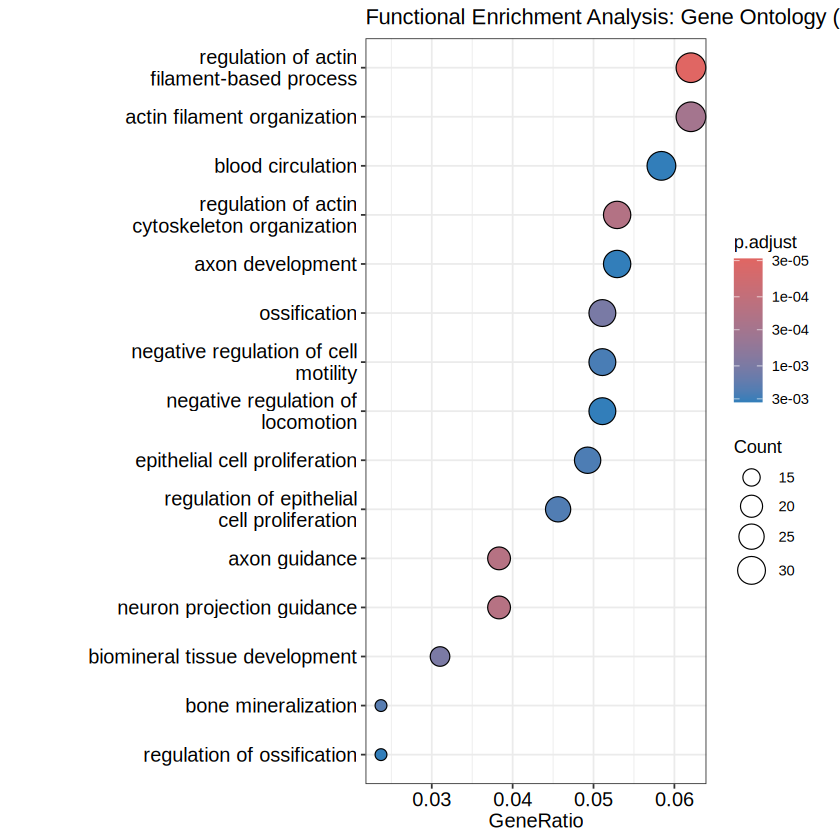

In [ ]:
# ==============================================================================
# Layer 2A (Part 2): Functional Enrichment Analysis (Gene Ontology - GO)
# Author: Mayada Mohammed Elfadil (M.Sc. in Bioinformatics)
# ==============================================================================

# Step 1: Install & Load Annotation Tools
if (!requireNamespace("BiocManager", quietly = TRUE)) install.packages("BiocManager")

BiocManager::install(c("clusterProfiler", "org.Hs.eg.db"), update = FALSE, ask = FALSE)

library(clusterProfiler)
library(org.Hs.eg.db)
library(dplyr)

cat("✅ Annotation Engine & Human Gene Database Loaded Successfully!\n\n")

# Step 2: Extract Significant DEG Symbols/Ensemble IDs
sig_gene_ids <- rownames(sig_genes)
sig_gene_ids_clean <- gsub("\\..*", "", sig_gene_ids)

# Step 3: Run Gene Ontology Biological Process (BP) Enrichment
go_results <- enrichGO(gene          = sig_gene_ids_clean,
                       OrgDb         = org.Hs.eg.db,
                       keyType       = 'ENSEMBL',
                       ont           = "BP", # Biological Process
                       pAdjustMethod = "BH",
                       pvalueCutoff  = 0.05,
                       qvalueCutoff  = 0.05)

# Step 4: Publication Visualizations for Enrichment Analysis
if (!is.null(go_results) && nrow(as.data.frame(go_results)) > 0) {

  cat("🔬 Top Enriched Biological Processes Identified:\n")
  print(head(as.data.frame(go_results)[, c("ID", "Description", "p.adjust")], 10))

  # A. Dotplot Visualization
  print(dotplot(go_results, showCategory = 15) +
        ggtitle("Functional Enrichment Analysis: Gene Ontology (Biological Process)"))

  # Export Enrichment Table to CSV
  write.csv(as.data.frame(go_results), "human_airway_GO_enrichment_results.csv")
  cat("\n✅ GO Enrichment Analysis Complete & Saved to 'human_airway_GO_enrichment_results.csv'!\n")

} else {
  cat("⚠️ No statistically significant GO terms found under current p-value thresholds.\n")
}